# DataSEC 2026 – Midterm: Environmental Sound Classification (22 lớp)

**Dataset (pinned):** Zenodo DOI `10.5281/zenodo.17033970` · **Task:** phân loại 22 macro-class trên log-Mel spectrogram.

Notebook này làm đủ Phần A–D của Project:
- A. Phân tích dataset (số clip, phân phối lớp, thống kê thời lượng, waveform / linear spectrogram / log-Mel, cân bằng lớp, các lớp có phổ giống nhau)
- B. Runtime feature pipeline (không lưu ảnh phổ ra đĩa)
- C. 3 mô hình: Small CNN, MobileNetV3-Small (ImageNet), CRNN (CNN + GRU)
- D. Metrics: Top-1, Macro-F1, per-class F1, confusion matrix, #params, MACs, latency, thời gian train



In [ ]:
!pip -q install soundfile librosa seaborn scikit-learn tqdm

In [ ]:
import os, sys, json, time, random, copy, zipfile, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchaudio, torchvision, soundfile as sf, librosa, librosa.display, sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# ---------------- CẤU HÌNH (sửa ở đây, không sửa rải rác trong code) ----------------
CFG = dict(
    dataset_doi="10.5281/zenodo.17033970",
    sample_rate=22050,      # Hz sau khi resample
    duration=4.0,           # giây, crop/pad cố định
    n_mels=128,
    n_fft=2048,
    hop_length=512,
    top_db=80,
    seed=42,
    split=(0.70, 0.15, 0.15),   # train / val / test, phân tầng theo lớp
    batch_size=64,
    epochs=30,
    patience=6,             # early stopping theo Macro-F1 trên val
    lr=1e-3,
    weight_decay=1e-4,
    num_workers=2,
)
FORCE_RETRAIN = False       # True = bỏ qua checkpoint cũ và train lại

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

SEED = CFG["seed"]
set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU")

Device: cuda | Tesla T4


In [ ]:
# ---------------- Đường dẫn: đọc zip từ Drive, giải nén ra đĩa cục bộ của Colab ----------------
import os, zipfile
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

DRIVE_BASE  = Path("/content/drive/MyDrive/ATI G6")
ZIP_PATH    = Path(os.environ.get("DATASEC_ZIP", str(DRIVE_BASE / "DATASEC.zip")))
EXTRACT_DIR = Path(os.environ.get("EXTRACT_DIR", "/content/DATASEC_extracted"))
OUT_DIR     = Path(os.environ.get("OUT_DIR", str(DRIVE_BASE / "datasec_midterm")))
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not any(EXTRACT_DIR.rglob("*.wav")):
    print(f"Đang giải nén từ {ZIP_PATH} (~6 GB, vài phút)...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)
ROOT = EXTRACT_DIR / "DATASEC" if (EXTRACT_DIR / "DATASEC").is_dir() else EXTRACT_DIR
print("ROOT    =", ROOT)
print("OUT_DIR =", OUT_DIR)

Mounted at /content/drive
Đang giải nén từ /content/drive/MyDrive/ATI G6/DATASEC.zip (~6 GB, vài phút)...
ROOT    = /content/DATASEC_extracted/DATASEC
OUT_DIR = /content/drive/MyDrive/ATI G6/datasec_midterm


## A. Phân tích dataset
Đọc header của từng file `.wav` (không load audio) để lấy thời lượng, sample rate, số kênh.
Cấu trúc thư mục: `macro_class/file.wav` hoặc `macro_class/subclass/file.wav`.
**Lưu ý:** subclass chỉ tồn tại khi có thư mục con. Lớp không có thư mục con *không* được tính là một subclass.

In [ ]:
rows = []
for p in sorted(ROOT.rglob("*.wav")):
    rel = p.relative_to(ROOT).parts
    if any(s.startswith(("__", ".")) for s in rel):
        continue
    try:
        info = sf.info(str(p))
    except Exception as e:
        print("Không đọc được:", p, e); continue
    rows.append(dict(
        sample_id=Path(*rel).as_posix(), path=str(p),
        macro_class=rel[0], subclass=rel[1] if len(rel) >= 3 else None,
        sr=info.samplerate, frames=info.frames, channels=info.channels,
        duration=info.frames / info.samplerate))
meta = pd.DataFrame(rows)

classes = sorted(meta.macro_class.unique())
K = len(classes)
class_to_idx = {c: i for i, c in enumerate(classes)}
meta["label"] = meta.macro_class.map(class_to_idx)

n_sub = meta.dropna(subset=["subclass"]).groupby(["macro_class", "subclass"]).ngroups
print(f"Số clip           : {len(meta)}   (đề ghi 4,292 -> đối chiếu với phiên bản Zenodo!)")
print(f"Macro-class       : {K}          (đề: 22)")
print(f"Subclass thật     : {n_sub}          (đề: 28)")
print(f"Tổng thời lượng   : {meta.duration.sum()/3600:.2f} giờ   (đề: ~18h26m)")
print("Sample rate       :", meta.sr.value_counts().to_dict())
print("Số kênh           :", meta.channels.value_counts().to_dict())

Số clip           : 5048   (đề ghi 4,292 -> đối chiếu với phiên bản Zenodo!)
Macro-class       : 22          (đề: 22)
Subclass thật     : 28          (đề: 28)
Tổng thời lượng   : 23.71 giờ   (đề: ~18h26m)
Sample rate       : {44100: 5048}
Số kênh           : {1: 5048}


macro_class
Voices                                      1900
Music                                       1001
Thunder fireworks and gunshot                235
Workshop                                     218
Vehicle pass-by                              217
Lawn mower brush cutter and olive shaker     127
Vehicle idling                               112
Glass breaking                               109
Propeller aircrafts                          108
Crows seagulls and magpies                   106
Sirens and alarms                            105
Jet aircrafts                                103
Wind turbine                                 100
Vacuum cleaner fan and hairdryer              95
Cicadas and crickets                          74
Dog barkings and howlings                     70
Birds                                         69
Bells                                         67
Train                                         67
Chicken coop                                  58
Horn    

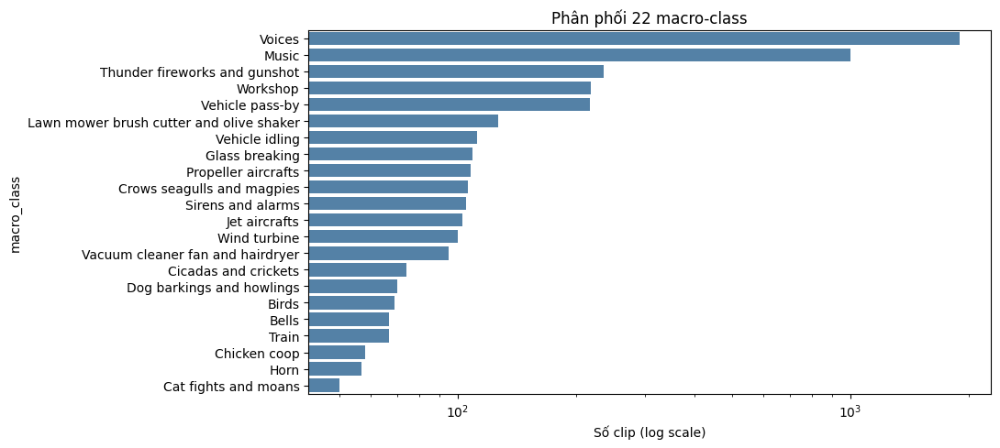

In [ ]:
# Phân phối lớp + đánh giá cân bằng
counts = meta.macro_class.value_counts().sort_values(ascending=False)
ratio = counts.max() / counts.min()
top2 = counts.iloc[:2].sum() / counts.sum()
print(counts.to_string())
print(f"\nTỉ lệ lớn nhất / nhỏ nhất = {counts.max()}/{counts.min()} = {ratio:.1f}x")
print(f"2 lớp lớn nhất ({counts.index[0]}, {counts.index[1]}) chiếm {top2*100:.1f}% dữ liệu -> mất cân bằng mạnh, Accuracy sẽ đánh lừa, dùng Macro-F1.")

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=counts.values, y=counts.index, ax=ax, color="steelblue")
ax.set_xscale("log"); ax.set_xlabel("Số clip (log scale)"); ax.set_title("Phân phối 22 macro-class")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_distribution.png", dpi=150); plt.show()

In [ ]:
# Thống kê thời lượng theo lớp (đủ 22 lớp) + tỉ lệ clip ngắn/dài hơn cửa sổ 4s
D = CFG["duration"]
dur_stats = meta.groupby("macro_class").duration.agg(count="count", min="min", max="max", mean="mean", median="median")
dur_stats["pct_shorter_than_4s"] = meta.groupby("macro_class").duration.apply(lambda s: (s < D).mean() * 100)
dur_stats = dur_stats.round(2)
dur_stats.to_csv(OUT_DIR / "duration_stats.csv")
pd.set_option("display.width", 200, "display.max_rows", 50)
print(dur_stats.to_string())

                                          count    min     max   mean  median  pct_shorter_than_4s
macro_class                                                                                       
Bells                                        67   2.71   73.08  28.59   29.64                10.45
Birds                                        69   1.97   79.97  13.16    5.00                10.14
Cat fights and moans                         50   2.39   66.97  23.41   19.97                 4.00
Chicken coop                                 58   0.98   55.14  11.95   11.30                32.76
Cicadas and crickets                         74   4.22   77.37  22.86   18.20                 0.00
Crows seagulls and magpies                  106   1.55  198.37  25.52   22.75                 5.66
Dog barkings and howlings                    70   0.35   37.74   9.61    7.56                32.86
Glass breaking                              109   0.24   60.53  36.64   60.52                22.94
Horn      

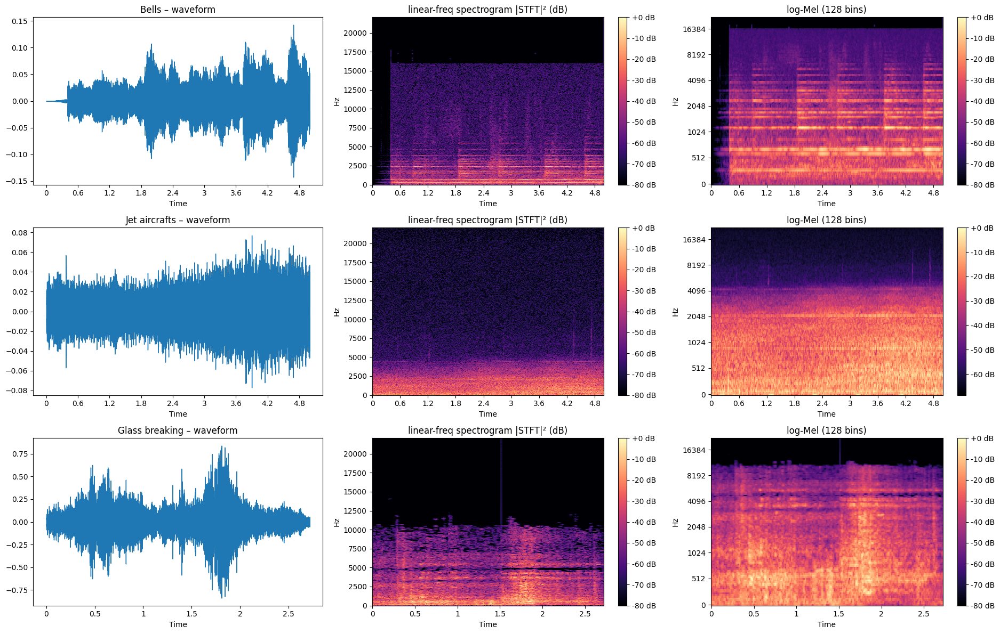

In [ ]:
# Waveform / linear-frequency spectrogram / log-Mel cho 3 lớp tương phản
# (tonal-harmonic, wideband ổn định, xung ngắn)
demo = [c for c in ["Bells", "Jet aircrafts", "Glass breaking"] if c in classes]
fig, axes = plt.subplots(len(demo), 3, figsize=(19, 4 * len(demo)))
axes = np.atleast_2d(axes)
for i, c in enumerate(demo):
    p = meta[meta.macro_class == c].iloc[0].path
    y, sr = librosa.load(p, sr=None, mono=True, duration=5.0)
    S = np.abs(librosa.stft(y, n_fft=CFG["n_fft"], hop_length=CFG["hop_length"])) ** 2
    librosa.display.waveshow(y, sr=sr, ax=axes[i, 0]);                axes[i, 0].set_title(f"{c} – waveform")
    im1 = librosa.display.specshow(librosa.power_to_db(S, ref=np.max), sr=sr, hop_length=CFG["hop_length"],
                                   x_axis="time", y_axis="linear", ax=axes[i, 1]); axes[i, 1].set_title("linear-freq spectrogram |STFT|² (dB)")
    M = librosa.feature.melspectrogram(S=S, sr=sr, n_mels=CFG["n_mels"])
    im2 = librosa.display.specshow(librosa.power_to_db(M, ref=np.max), sr=sr, hop_length=CFG["hop_length"],
                                   x_axis="time", y_axis="mel", ax=axes[i, 2]); axes[i, 2].set_title(f"log-Mel ({CFG['n_mels']} bins)")
    fig.colorbar(im1, ax=axes[i, 1], format="%+2.0f dB"); fig.colorbar(im2, ax=axes[i, 2], format="%+2.0f dB")
plt.tight_layout(); plt.savefig(OUT_DIR / "waveform_spectrogram_logmel.png", dpi=130); plt.show()

### Ba biểu diễn: khác nhau về toán học và vật lý
1. **Waveform** $x[n]$: chuỗi mẫu của áp suất âm theo thời gian, lấy mẫu tại $f_s$. Chứa đầy đủ thông tin (pha + biên độ) nhưng tần số và cấu trúc hài không "nhìn thấy" trực tiếp.
2. **Linear-frequency spectrogram**: $S(m,k)=\left|\sum_{n} x[n+mH]\,w[n]\,e^{-j2\pi kn/N}\right|^2$ — năng lượng ở mỗi vạch tần số $f_k=k f_s/N$ cách đều nhau tại từng khung thời gian $m$ (cửa sổ $w$, bước nhảy $H$). Mất pha, đánh đổi độ phân giải thời gian–tần số theo $N$.
3. **Log-Mel spectrogram**: thang Mel $m(f)=2595\log_{10}(1+f/700)$ mô phỏng thính giác (nhạy ở tần số thấp, thô ở tần số cao). Nhân $S$ với ma trận bộ lọc tam giác $\mathbf{M}\in\mathbb{R}^{n_{mels}\times(N/2+1)}$ rồi nén động học: $L=10\log_{10}\max(\mathbf{M}S,\varepsilon)$ (dB, cắt `top_db`=80). Giảm từ 1025 chiều tần số xuống 128, nén dải động ~ cảm nhận độ to, ổn định hơn cho CNN.

## Chia dữ liệu (phân tầng, cố định, lưu file index)
Train/val/test = 70/15/15, **phân tầng theo macro-class**, `seed=42`. Val dùng để early stopping, **test chỉ dùng một lần ở cuối** và là test set sạch dùng lại ở Final.

> Giới hạn cần ghi vào báo cáo: nếu nhiều clip được cắt từ cùng một bản ghi dài, split ngẫu nhiên theo clip có thể bị rò rỉ giữa train và test. Dataset không cung cấp ID bản ghi nên không kiểm soát được.

In [ ]:
idx = np.arange(len(meta))
tv_frac = CFG["split"][1] + CFG["split"][2]
tr, tmp = train_test_split(idx, test_size=tv_frac, stratify=meta.label, random_state=SEED)
va, te = train_test_split(tmp, test_size=CFG["split"][2] / tv_frac, stratify=meta.label.iloc[tmp], random_state=SEED)
meta["split"] = "train"
meta.loc[va, "split"] = "val"
meta.loc[te, "split"] = "test"
meta[["sample_id", "macro_class", "subclass", "label", "split"]].to_csv(OUT_DIR / "split_indices.csv", index=False)

print(meta.split.value_counts().to_string())
print(pd.crosstab(meta.macro_class, meta.split).to_string())

split
train    3533
test      758
val       757
split                                     test  train  val
macro_class                                               
Bells                                       10     47   10
Birds                                       10     48   11
Cat fights and moans                         7     35    8
Chicken coop                                 8     41    9
Cicadas and crickets                        11     52   11
Crows seagulls and magpies                  16     74   16
Dog barkings and howlings                   10     49   11
Glass breaking                              17     76   16
Horn                                         8     40    9
Jet aircrafts                               16     72   15
Lawn mower brush cutter and olive shaker    19     89   19
Music                                      150    701  150
Propeller aircrafts                         16     76   16
Sirens and alarms                           16     73   16
Thunder 

## B. Runtime feature pipeline
`wav → đọc đúng cửa sổ 4 s → mono → resample 22.05 kHz → crop/pad → (trên GPU) log-Mel 128 bins → chuẩn hóa toàn cục → mạng`

- Train: **crop ngẫu nhiên** với clip dài hơn 4 s (augmentation nhẹ, không tối ưu theo test). Val/test: **crop giữa**, xác định.
- Clip ngắn hơn 4 s được pad 0 ở cuối.
- Chuẩn hóa dùng **mean/std toàn cục của train** (không chuẩn hóa theo từng clip), để thay đổi gain ở phần Final vẫn có ý nghĩa.
- Không có file ảnh phổ nào được ghi ra đĩa.

In [ ]:
TARGET = int(round(CFG["duration"] * CFG["sample_rate"]))

class AudioDS(Dataset):
    def __init__(self, df, train=False):
        df = df.reset_index(drop=True)
        self.paths = df.path.tolist(); self.sr = df.sr.astype(int).tolist()
        self.frames = df.frames.astype(int).tolist(); self.labels = df.label.astype(int).tolist()
        self.train = train; self._rs = {}
    def __len__(self): return len(self.paths)
    def _resampler(self, sr):
        if sr not in self._rs:
            self._rs[sr] = torchaudio.transforms.Resample(sr, CFG["sample_rate"])
        return self._rs[sr]
    def __getitem__(self, i):
        sr, n = self.sr[i], self.frames[i]
        need = int(round(CFG["duration"] * sr))
        start = (random.randint(0, n - need) if self.train else (n - need) // 2) if n > need else 0
        y, _ = sf.read(self.paths[i], start=start, frames=min(need, n), dtype="float32", always_2d=True)
        y = torch.from_numpy(y.mean(axis=1))                 # mono
        if sr != CFG["sample_rate"]:
            y = self._resampler(sr)(y)
        y = y[:TARGET]
        if y.numel() < TARGET:
            y = F.pad(y, (0, TARGET - y.numel()))            # pad 0 ở cuối
        return y.unsqueeze(0), self.labels[i], i

def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(ds, shuffle, drop_last=False, bs=None):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=bs or CFG["batch_size"], shuffle=shuffle, drop_last=drop_last,
                      num_workers=CFG["num_workers"], pin_memory=(DEVICE.type == "cuda"),
                      persistent_workers=CFG["num_workers"] > 0, worker_init_fn=seed_worker, generator=g)

train_df, val_df, test_df = (meta[meta.split == s] for s in ["train", "val", "test"])
train_ds, val_ds, test_ds = AudioDS(train_df, True), AudioDS(val_df), AudioDS(test_df)
train_loader = make_loader(train_ds, True, drop_last=True)
val_loader, test_loader = make_loader(val_ds, False, bs=128), make_loader(test_ds, False, bs=128)

class LogMel(nn.Module):
    def __init__(self):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=CFG["sample_rate"], n_fft=CFG["n_fft"], hop_length=CFG["hop_length"],
            n_mels=CFG["n_mels"], power=2.0)
        self.db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=CFG["top_db"])
        self.register_buffer("mean", torch.tensor(0.0)); self.register_buffer("std", torch.tensor(1.0))
    def forward(self, wav):                                   # wav: [B,1,T] -> [B,1,n_mels,frames]
        with torch.autocast(device_type=wav.device.type, enabled=False):
            x = self.db(self.mel(wav.float()))
        return (x - self.mean) / self.std

frontend = LogMel().to(DEVICE)

# mean/std toàn cục ước lượng trên 512 clip train
rng = np.random.RandomState(SEED)
sub = Subset(train_ds, rng.choice(len(train_ds), min(512, len(train_ds)), replace=False).tolist())
vals = []
with torch.no_grad():
    for wav, _, _ in DataLoader(sub, batch_size=64, num_workers=CFG["num_workers"]):
        vals.append(frontend(wav.to(DEVICE)).flatten().cpu())
vals = torch.cat(vals)
frontend.mean.fill_(vals.mean().item()); frontend.std.fill_(vals.std().item())
CFG["norm_mean"], CFG["norm_std"] = float(vals.mean()), float(vals.std())

with torch.no_grad():
    T_FRAMES = frontend(torch.zeros(1, 1, TARGET, device=DEVICE)).shape[-1]
print(f"Input mạng: [B, 1, {CFG['n_mels']}, {T_FRAMES}] | norm mean={CFG['norm_mean']:.2f} std={CFG['norm_std']:.2f}")

Input mạng: [B, 1, 128, 173] | norm mean=-9.34 std=22.10


10 cặp lớp có đường bao phổ giống nhau nhất (tương quan):
  +0.93  Cicadas and crickets  <->  Glass breaking
  +0.93  Jet aircrafts  <->  Thunder fireworks and gunshot
  +0.92  Jet aircrafts  <->  Propeller aircrafts
  +0.91  Music  <->  Thunder fireworks and gunshot
  +0.90  Propeller aircrafts  <->  Thunder fireworks and gunshot
  +0.89  Music  <->  Propeller aircrafts
  +0.88  Train  <->  Vacuum cleaner fan and hairdryer
  +0.88  Jet aircrafts  <->  Music
  +0.87  Vacuum cleaner fan and hairdryer  <->  Vehicle idling
  +0.85  Vacuum cleaner fan and hairdryer  <->  Wind turbine


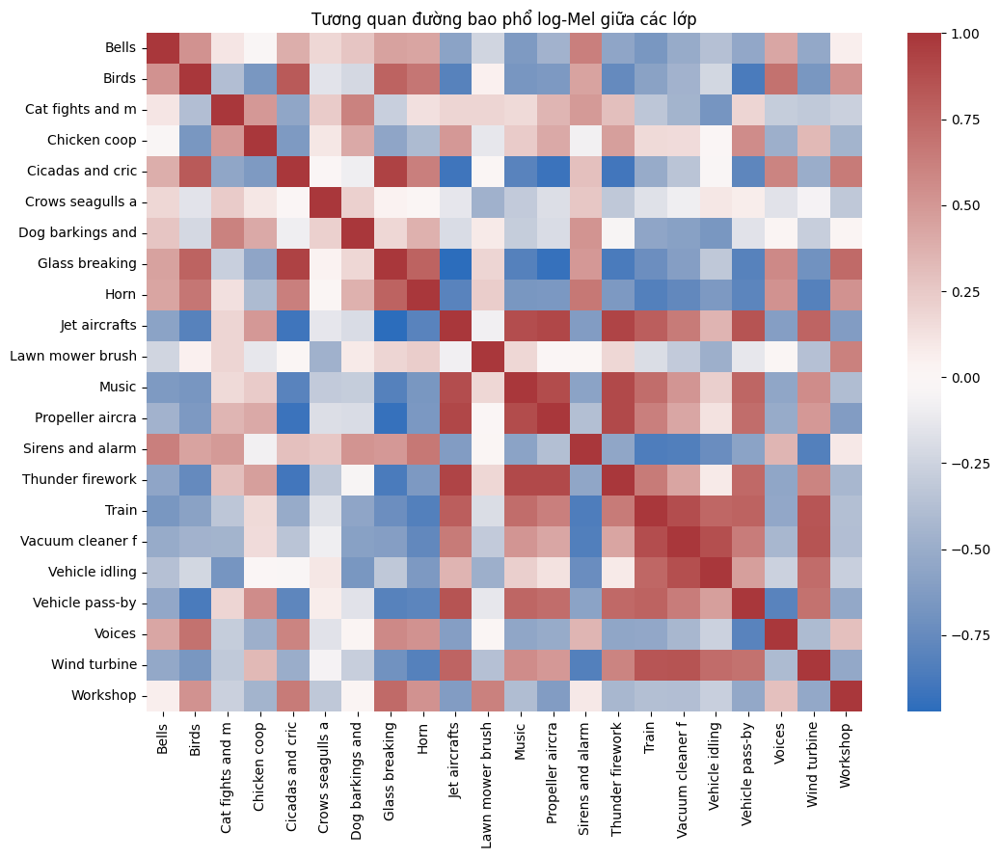

In [ ]:
# Lớp nào có phổ trung bình giống nhau? (đường bao phổ theo tần số, trung bình theo thời gian)
env = {}
with torch.no_grad():
    for c in classes:
        sub_df = train_df[train_df.macro_class == c].head(12)
        ds = AudioDS(sub_df)
        wav = torch.stack([ds[i][0] for i in range(len(ds))]).to(DEVICE)
        env[c] = frontend(wav).mean(dim=(0, 1, 3)).cpu().numpy()      # [n_mels]
E = np.stack([env[c] for c in classes]); E = E - E.mean(0, keepdims=True)  # bỏ hình dạng chung của mọi lớp
C = np.corrcoef(E)
pairs = sorted([(classes[i], classes[j], C[i, j]) for i in range(K) for j in range(i + 1, K)], key=lambda t: -t[2])
print("10 cặp lớp có đường bao phổ giống nhau nhất (tương quan):")
for a, b, r in pairs[:10]:
    print(f"  {r:+.2f}  {a}  <->  {b}")
plt.figure(figsize=(11, 9)); sns.heatmap(C, xticklabels=[c[:16] for c in classes], yticklabels=[c[:16] for c in classes], cmap="vlag", center=0)
plt.title("Tương quan đường bao phổ log-Mel giữa các lớp"); plt.tight_layout()
plt.savefig(OUT_DIR / "spectral_envelope_similarity.png", dpi=140); plt.show()

## C. Mô hình
- **Small CNN**: 3 khối Conv-BN-ReLU + global average pooling.
- **MobileNetV3-Small**: trọng số ImageNet, thay lớp cuối thành 22 lớp, kênh phổ đơn được nhân ra 3 kênh bên trong mô hình.
- **CRNN**: 2 khối CNN → GRU hai chiều → **mean + max pooling theo thời gian** (bản cũ lấy bước cuối nên với clip ngắn chỉ nhìn thấy phần pad im lặng).

In [ ]:
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class SmallCNN(nn.Module):
    def __init__(self, k=22):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 32), nn.MaxPool2d(2), conv_block(32, 64), nn.MaxPool2d(2),
                                      conv_block(64, 128), nn.AdaptiveAvgPool2d(1))
        self.drop = nn.Dropout(0.3); self.fc = nn.Linear(128, k)
    def forward(self, x):
        return self.fc(self.drop(torch.flatten(self.features(x), 1)))

class MobileNetV3S(nn.Module):
    def __init__(self, k=22):
        super().__init__()
        m = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, k)
        self.m = m
    def forward(self, x):
        return self.m(x.expand(-1, 3, -1, -1))             # 1 kênh -> 3 kênh

class CRNN(nn.Module):
    def __init__(self, k=22, n_mels=CFG["n_mels"], hidden=128):
        super().__init__()
        self.cnn = nn.Sequential(conv_block(1, 32), nn.MaxPool2d(2), conv_block(32, 64), nn.MaxPool2d(2))
        self.gru = nn.GRU(64 * (n_mels // 4), hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3); self.fc = nn.Linear(4 * hidden, k)
    def forward(self, x):
        x = self.cnn(x)                                    # [B,64,F/4,T/4]
        x = x.permute(0, 3, 1, 2).flatten(2)               # [B,T/4,64*F/4]
        out, _ = self.gru(x)
        feat = torch.cat([out.mean(1), out.amax(1)], dim=1)
        return self.fc(self.drop(feat))

MODELS = {"Small CNN": SmallCNN, "MobileNetV3-Small": MobileNetV3S, "CRNN": CRNN}

with torch.no_grad():
    dummy = torch.zeros(2, 1, CFG["n_mels"], T_FRAMES)
    for n, M in MODELS.items():
        print(f"{n:20s} -> {tuple(M(K).eval()(dummy).shape)}")

Small CNN            -> (2, 22)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 192MB/s]

MobileNetV3-Small    -> (2, 22)
CRNN                 -> (2, 22)


In [ ]:
# Class weight (căn bậc hai nghịch đảo tần suất) để giảm tác động của mất cân bằng
tc = train_df.label.value_counts().reindex(range(K)).values.astype(float)
CLASS_W = torch.tensor((tc.sum() / (K * tc)) ** 0.5, dtype=torch.float32)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); P, Y, I = [], [], []
    for wav, y, i in loader:
        x = frontend(wav.to(DEVICE, non_blocking=True))
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
        P.append(torch.softmax(logits.float(), 1).cpu()); Y.append(y); I.append(i)
    P, Y, I = torch.cat(P).numpy(), torch.cat(Y).numpy(), torch.cat(I).numpy()
    pred = P.argmax(1)
    return dict(probs=P, labels=Y, preds=pred, idx=I, acc=accuracy_score(Y, pred),
                macro_f1=f1_score(Y, pred, average="macro", labels=list(range(K)), zero_division=0))

def fit(name, model):
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"])
    crit = nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []
    t0 = time.time()
    for ep in range(1, CFG["epochs"] + 1):
        model.train(); tot = n = 0
        for wav, y, _ in train_loader:
            wav, y = wav.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.no_grad():
                x = frontend(wav)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        v = evaluate(model, val_loader)
        hist.append(dict(epoch=ep, train_loss=tot / n, val_acc=v["acc"], val_macro_f1=v["macro_f1"]))
        print(f"[{name}] ep {ep:02d} loss {tot/n:.4f} | val acc {v['acc']*100:.2f}% macroF1 {v['macro_f1']:.4f}")
        if v["macro_f1"] > best:
            best, best_ep, bad = v["macro_f1"], ep, 0
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"[{name}] early stop tại epoch {ep}"); break
    return dict(state=best_state, history=hist, best_epoch=best_ep, epochs_run=len(hist), train_time_s=time.time() - t0)

CKPT = {}
for name, M in MODELS.items():
    path = OUT_DIR / f"ckpt_{name.replace(' ', '_')}.pt"
    if path.exists() and not FORCE_RETRAIN:
        CKPT[name] = torch.load(path, map_location="cpu", weights_only=False)
        print(f"[{name}] đã có checkpoint, bỏ qua train.")
        continue
    set_seed(SEED)
    CKPT[name] = fit(name, M(K))
    torch.save(CKPT[name], path)

[Small CNN] đã có checkpoint, bỏ qua train.
[MobileNetV3-Small] đã có checkpoint, bỏ qua train.
[CRNN] đã có checkpoint, bỏ qua train.


## D. Đánh giá trên **test set** (một lần, dùng checkpoint tốt nhất theo val)

In [ ]:
def build(name):
    m = MODELS[name](K); m.load_state_dict(CKPT[name]["state"]); return m.to(DEVICE).eval()

def count_params(m): return sum(p.numel() for p in m.parameters())

def count_macs(model):
    # MACs cho 1 clip (không gồm front-end log-Mel). Conv/Linear theo hook, GRU tính theo công thức.
    macs = [0]; hooks = []
    def conv_h(m, i, o): macs[0] += o.numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
    def lin_h(m, i, o): macs[0] += o.numel() * m.in_features
    def gru_h(m, i, o):
        B, T, din = i[0].shape; d = 2 if m.bidirectional else 1; h = m.hidden_size
        assert m.num_layers == 1
        macs[0] += B * T * d * 3 * (din * h + h * h)
    m = copy.deepcopy(model).cpu().eval()
    for mod in m.modules():
        if isinstance(mod, nn.Conv2d): hooks.append(mod.register_forward_hook(conv_h))
        elif isinstance(mod, nn.Linear): hooks.append(mod.register_forward_hook(lin_h))
        elif isinstance(mod, nn.GRU): hooks.append(mod.register_forward_hook(gru_h))
    with torch.no_grad(): m(torch.zeros(1, 1, CFG["n_mels"], T_FRAMES))
    for h in hooks: h.remove()
    return macs[0]

def latency_ms(model, n=100):
    # wav (đã nằm trên thiết bị) -> log-Mel -> logits, batch=1; không gồm thời gian đọc đĩa
    wav = torch.randn(1, 1, TARGET, device=DEVICE)
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    with torch.no_grad():
        for _ in range(10): model(frontend(wav))
        sync(); t = time.perf_counter()
        for _ in range(n): model(frontend(wav))
        sync()
    return (time.perf_counter() - t) / n * 1000

R = {}
for name in MODELS:
    model = build(name)
    R[name] = dict(val=evaluate(model, val_loader), test=evaluate(model, test_loader),
                   params=count_params(model), gmacs=count_macs(build(name)) / 1e9, latency_ms=latency_ms(model))

summary = pd.DataFrame([dict(
    model=n, params_M=r["params"] / 1e6, GMACs=r["gmacs"], latency_ms=r["latency_ms"],
    train_time_s=CKPT[n]["train_time_s"], epochs_run=CKPT[n]["epochs_run"], best_epoch=CKPT[n]["best_epoch"],
    val_acc=r["val"]["acc"], val_macroF1=r["val"]["macro_f1"],
    test_acc=r["test"]["acc"], test_macroF1=r["test"]["macro_f1"]) for n, r in R.items()]).round(4)
summary.to_csv(OUT_DIR / "baseline_results.csv", index=False)
print(summary.to_string(index=False))

            model  params_M  GMACs  latency_ms  train_time_s  epochs_run  best_epoch  val_acc  val_macroF1  test_acc  test_macroF1
        Small CNN    0.0960 0.2093      1.2306      415.5396          30          28   0.8613       0.7158    0.8615        0.7140
MobileNetV3-Small    1.5404 0.0262      6.5889      359.6270          26          20   0.9551       0.9133    0.9485        0.8975
             CRNN    1.7030 0.1797      1.3980      376.3251          30          28   0.9194       0.8332    0.9195        0.8363


In [ ]:
# Lưu xác suất dự đoán (khớp schema của Final): clean -> perturbation="clean", severity=0
out = []
for name, r in R.items():
    for split in ["val", "test"]:
        e = r[split]; df_s = val_df if split == "val" else test_df
        df_s = df_s.reset_index(drop=True)
        for k in range(len(e["idx"])):
            row = df_s.iloc[e["idx"][k]]
            out.append(dict(sample_id=row.sample_id, true_class=classes[e["labels"][k]], pred_class=classes[e["preds"][k]],
                            probabilities=json.dumps([round(float(p), 5) for p in e["probs"][k]]),
                            duration=round(float(row.duration), 3), model=name, split=split,
                            perturbation="clean", severity=0))
pd.DataFrame(out).to_csv(OUT_DIR / "predictions_clean.csv", index=False)
print("Đã lưu predictions_clean.csv:", len(out), "dòng")

Đã lưu predictions_clean.csv: 4545 dòng


In [ ]:
# F1 theo lớp (test) + lớp tốt nhất / kém nhất
pc = pd.DataFrame({n: pd.Series(classification_report(r["test"]["labels"], r["test"]["preds"], labels=list(range(K)),
                                                       target_names=classes, output_dict=True, zero_division=0)).drop(
        ["accuracy", "macro avg", "weighted avg"]).apply(lambda d: d["f1-score"]) for n, r in R.items()})
pc["n_test"] = test_df.macro_class.value_counts().reindex(classes).values
pc = pc.round(3); pc.to_csv(OUT_DIR / "per_class_f1_test.csv")
print(pc.to_string())
for n in MODELS:
    s = pc[n].sort_values()
    print(f"\n{n}: thấp nhất -> {', '.join(f'{c} ({v:.2f})' for c, v in s.head(3).items())}")
    print(f"{n}: cao nhất  -> {', '.join(f'{c} ({v:.2f})' for c, v in s.tail(3).items())}")

                                          Small CNN  MobileNetV3-Small   CRNN  n_test
Bells                                         0.737              1.000  0.952      10
Birds                                         0.556              0.842  0.947      10
Cat fights and moans                          0.667              1.000  0.833       7
Chicken coop                                  0.714              1.000  0.889       8
Cicadas and crickets                          0.833              0.870  0.900      11
Crows seagulls and magpies                    0.733              0.909  0.903      16
Dog barkings and howlings                     0.706              1.000  0.842      10
Glass breaking                                0.941              0.970  0.944      17
Horn                                          0.667              0.800  0.933       8
Jet aircrafts                                 0.514              0.857  0.839      16
Lawn mower brush cutter and olive shaker      0.638   

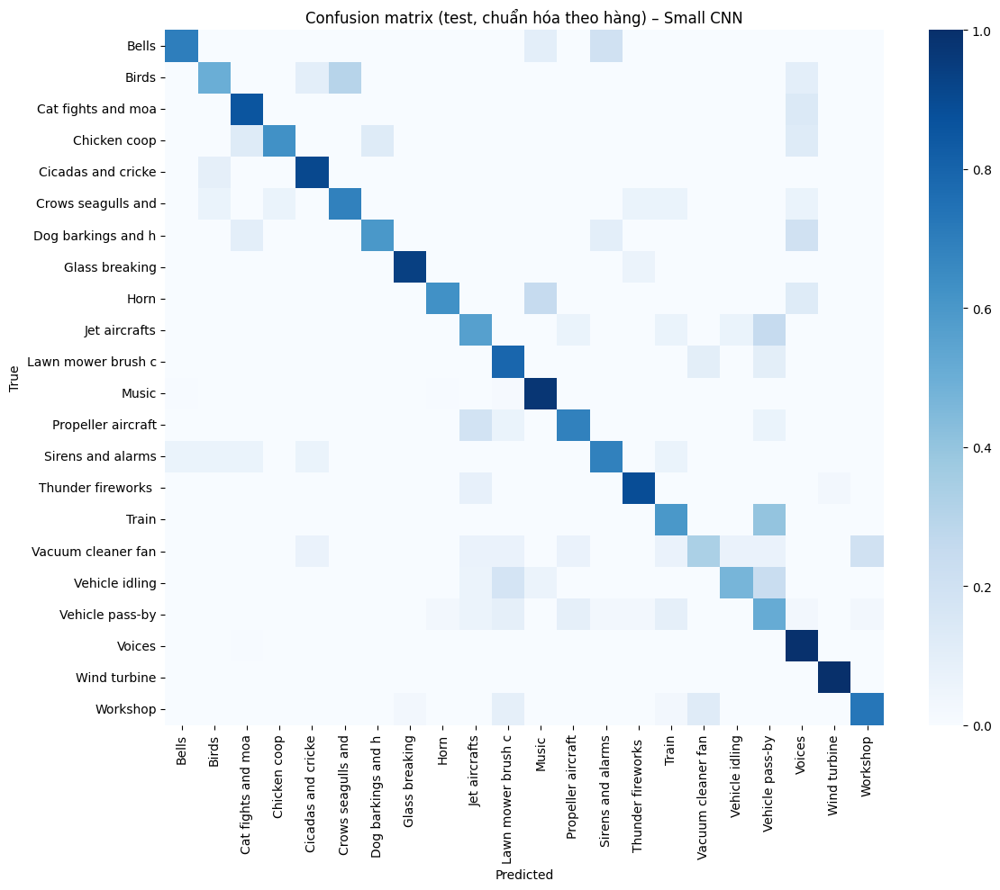

Cặp nhầm lẫn nhiều nhất – Small CNN
                            true                  predicted  count  share_of_true_class
                           Train            Vehicle pass-by      4                 0.40
                           Birds Crows seagulls and magpies      3                 0.30
                            Horn                      Music      2                 0.25
                   Jet aircrafts            Vehicle pass-by      4                 0.25
                  Vehicle idling            Vehicle pass-by      4                 0.24
                           Bells          Sirens and alarms      2                 0.20
       Dog barkings and howlings                     Voices      2                 0.20
Vacuum cleaner fan and hairdryer                   Workshop      3                 0.20



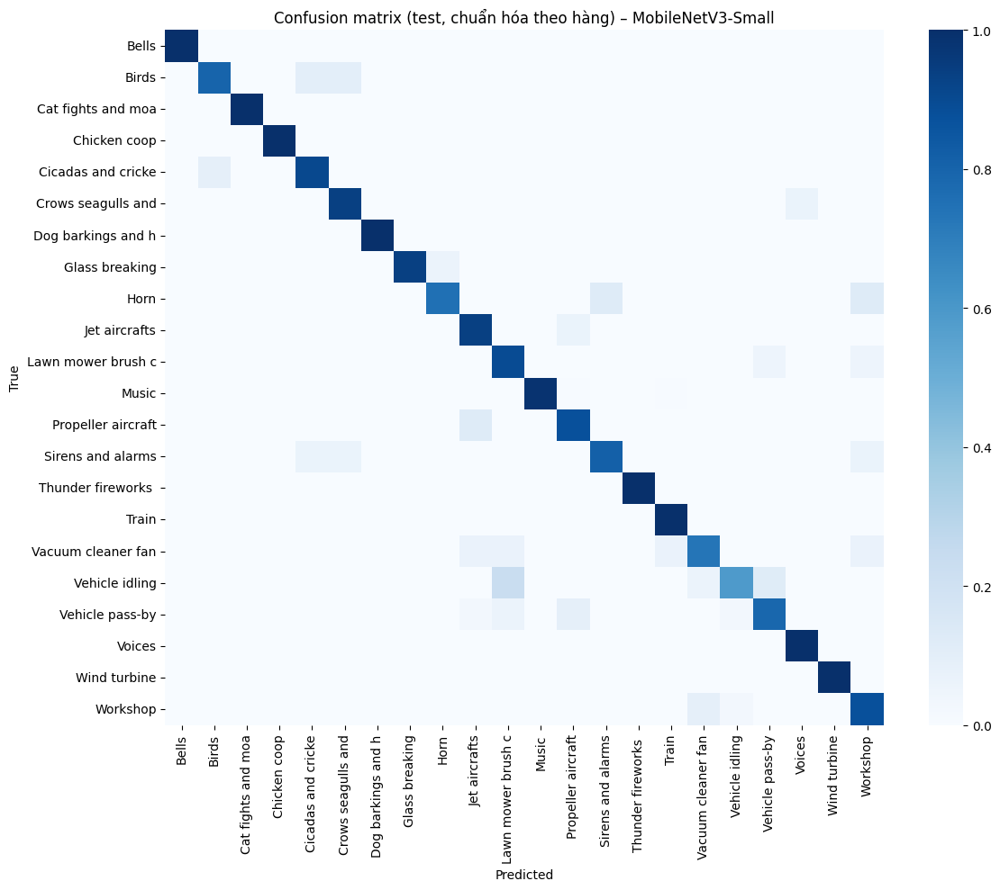

Cặp nhầm lẫn nhiều nhất – MobileNetV3-Small
               true                                predicted  count  share_of_true_class
     Vehicle idling Lawn mower brush cutter and olive shaker      4                 0.24
Propeller aircrafts                            Jet aircrafts      2                 0.12
     Vehicle idling                          Vehicle pass-by      2                 0.12
    Vehicle pass-by                      Propeller aircrafts      3                 0.09
           Workshop         Vacuum cleaner fan and hairdryer      3                 0.09
    Vehicle pass-by Lawn mower brush cutter and olive shaker      2                 0.06



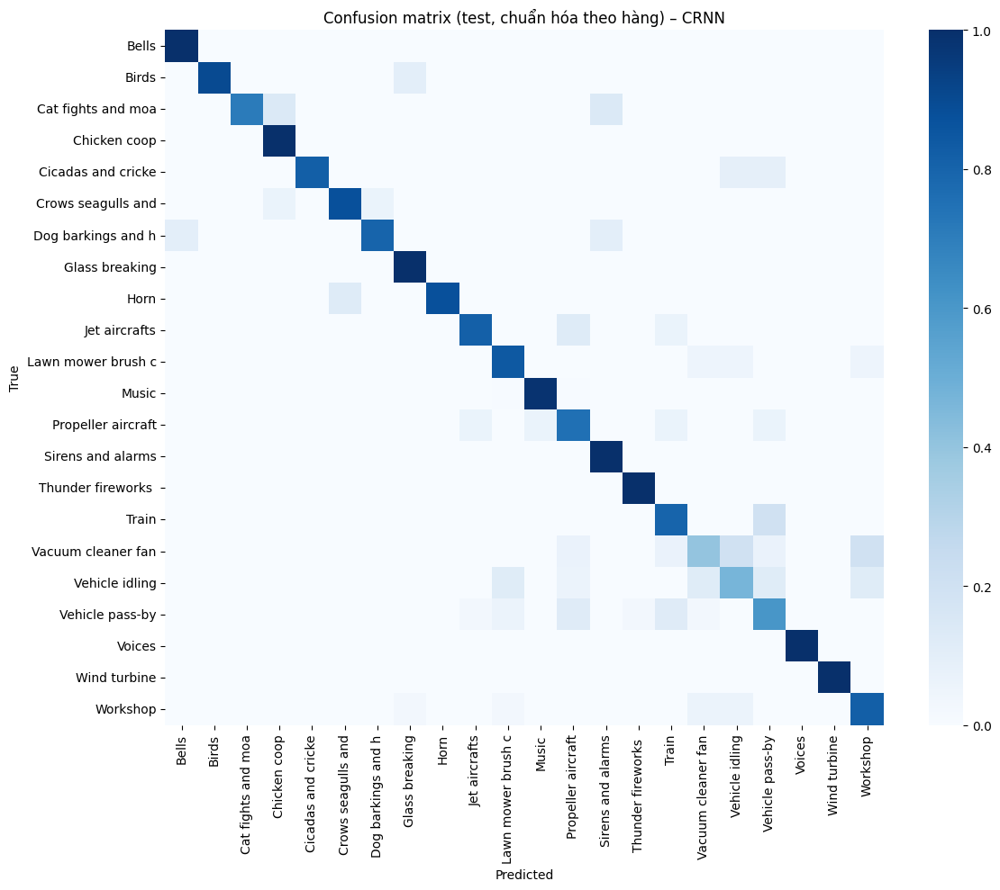

Cặp nhầm lẫn nhiều nhất – CRNN
                            true                                predicted  count  share_of_true_class
                           Train                          Vehicle pass-by      2                 0.20
Vacuum cleaner fan and hairdryer                           Vehicle idling      3                 0.20
Vacuum cleaner fan and hairdryer                                 Workshop      3                 0.20
                   Jet aircrafts                      Propeller aircrafts      2                 0.12
                  Vehicle idling Lawn mower brush cutter and olive shaker      2                 0.12
                  Vehicle idling         Vacuum cleaner fan and hairdryer      2                 0.12
                  Vehicle idling                          Vehicle pass-by      2                 0.12
                  Vehicle idling                                 Workshop      2                 0.12



In [ ]:
# Confusion matrix (chuẩn hóa theo hàng, có nhãn) + các cặp nhầm lẫn nhiều nhất
def top_confusions(cm, k=8):
    c = cm.copy(); np.fill_diagonal(c, 0); rows = []
    for i in range(K):
        for j in range(K):
            if c[i, j] >= 2:
                rows.append((classes[i], classes[j], int(c[i, j]), round(c[i, j] / cm[i].sum(), 2)))
    return pd.DataFrame(sorted(rows, key=lambda t: -t[3])[:k], columns=["true", "predicted", "count", "share_of_true_class"])

for n, r in R.items():
    cm = confusion_matrix(r["test"]["labels"], r["test"]["preds"], labels=list(range(K)))
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1,
                xticklabels=[c[:18] for c in classes], yticklabels=[c[:18] for c in classes])
    plt.title(f"Confusion matrix (test, chuẩn hóa theo hàng) – {n}"); plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout(); plt.savefig(OUT_DIR / f"cm_{n.replace(' ', '_')}.png", dpi=140); plt.show()
    print(f"Cặp nhầm lẫn nhiều nhất – {n}"); print(top_confusions(cm).to_string(index=False)); print()

In [ ]:
# Câu hỏi 3: độ chính xác theo độ dài clip (CRNN có hơn CNN trên clip có độ dài khác nhau không?)
bins = [0, 1, 2, 4, 10, 1e9]; labels_b = ["<1s", "1-2s", "2-4s", "4-10s", ">10s"]
dts = test_df.reset_index(drop=True)
bucket = pd.cut(dts.duration.values[R["CRNN"]["test"]["idx"]], bins=bins, labels=labels_b)
tab = {}
for n, r in R.items():
    ok = (r["test"]["preds"] == r["test"]["labels"])
    tab[n] = pd.Series(ok).groupby(bucket, observed=True).mean()
tab = pd.DataFrame(tab).round(3); tab.index = tab.index.astype(str); tab["n_clips"] = pd.Series(bucket).value_counts().reindex(labels_b)
tab.to_csv(OUT_DIR / "accuracy_by_duration.csv"); print(tab.to_string())

       Small CNN  MobileNetV3-Small   CRNN  n_clips
<1s        0.958              1.000  0.986       71
1-2s       0.987              1.000  1.000       79
2-4s       0.886              0.990  0.952      105
4-10s      0.832              0.933  0.893      149
>10s       0.819              0.921  0.890      354


In [ ]:
# Câu hỏi 4: trade-off hiệu năng / chi phí tính toán (Pareto theo Macro-F1 và GMACs)
s = summary.set_index("model")
def dominated(m):
    return any((s.loc[o, "GMACs"] <= s.loc[m, "GMACs"]) and (s.loc[o, "test_macroF1"] >= s.loc[m, "test_macroF1"]) and
               ((s.loc[o, "GMACs"] < s.loc[m, "GMACs"]) or (s.loc[o, "test_macroF1"] > s.loc[m, "test_macroF1"]))
               for o in s.index if o != m)
s["pareto_efficient"] = [not dominated(m) for m in s.index]
print(s[["params_M", "GMACs", "latency_ms", "train_time_s", "test_macroF1", "pareto_efficient"]].to_string())

                   params_M   GMACs  latency_ms  train_time_s  test_macroF1  pareto_efficient
model                                                                                        
Small CNN            0.0960  0.2093      1.2306      415.5396        0.7140             False
MobileNetV3-Small    1.5404  0.0262      6.5889      359.6270        0.8975              True
CRNN                 1.7030  0.1797      1.3980      376.3251        0.8363             False


## Error audit định tính
Các mẫu test bị đoán sai **với độ tin cậy cao nhất** của mô hình tốt nhất. Nghe lại từng clip và ghi nhận xét (nhiễu nền, nhiều nguồn âm cùng lúc, nhãn mơ hồ, clip quá ngắn...) vào báo cáo.

In [ ]:
from IPython.display import display, Audio
best_name = summary.sort_values("test_macroF1").iloc[-1].model
e = R[best_name]["test"]; dts = test_df.reset_index(drop=True)
wrong = np.where(e["preds"] != e["labels"])[0]
wrong = wrong[np.argsort(-e["probs"][wrong, e["preds"][wrong]])][:20]
audit = pd.DataFrame([dict(sample_id=dts.sample_id[e["idx"][k]], true=classes[e["labels"][k]], predicted=classes[e["preds"][k]],
                           confidence=round(float(e["probs"][k, e["preds"][k]]), 3),
                           duration_s=round(float(dts.duration[e["idx"][k]]), 2), path=dts.path[e["idx"][k]]) for k in wrong])
audit.drop(columns="path").to_csv(OUT_DIR / "error_audit.csv", index=False)
print("Mô hình tốt nhất:", best_name, "| số mẫu sai:", int((e["preds"] != e["labels"]).sum()), "/", len(e["labels"]))
print(audit.drop(columns="path").to_string(index=False))
for _, row in audit.head(3).iterrows():
    print(f"\n{row.true}  ->  nhận nhầm là  {row.predicted}  ({row.confidence})")
    display(Audio(filename=row.path))

Mô hình tốt nhất: MobileNetV3-Small | số mẫu sai: 39 / 758
                                                              sample_id                             true                                predicted  confidence  duration_s
                       Propeller aircrafts/Airplanes/Airplanes-0004.wav              Propeller aircrafts                            Jet aircrafts       0.999       10.99
                        Workshop/air compressor/air compressor-0028.wav                         Workshop         Vacuum cleaner fan and hairdryer       0.984       35.91
              Vehicle idling/car truck idling/car truck idling-0034.wav                   Vehicle idling                          Vehicle pass-by       0.982       40.82
                                                   Music/Music-0774.wav                            Music                                    Train       0.980       30.00
              Vehicle idling/motorbike idling/motorbike idling-0029.wav                   V


Workshop  ->  nhận nhầm là  Vacuum cleaner fan and hairdryer  (0.984)



Vehicle idling  ->  nhận nhầm là  Vehicle pass-by  (0.982)


In [ ]:
# Lưu cấu hình + phiên bản thư viện (yêu cầu tái lập)
CFG["classes"] = classes
CFG["env"] = dict(python=platform.python_version(), torch=torch.__version__, torchaudio=torchaudio.__version__,
                  torchvision=torchvision.__version__, librosa=librosa.__version__, soundfile=sf.__version__,
                  sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__)
json.dump(CFG, open(OUT_DIR / "config.json", "w"), indent=2, ensure_ascii=False)
print("Đã lưu config.json. Toàn bộ kết quả nằm trong:", OUT_DIR)

Đã lưu config.json. Toàn bộ kết quả nằm trong: /content/drive/MyDrive/ATI G6/datasec_midterm
